# GLM

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import statsmodels.api as sm
import statsmodels.formula.api as smf

from pathlib import Path
current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1) Stimulus
rng = np.random.default_rng(0)
n = 20000
x = rng.normal(0, 1.0, size=n)
y = rng.normal(0, 1.0, size=n)

# 2) Rotated *coordinate* helper (returns u only; no Gaussian here)
def rotated_coord(x, y, c, theta, wrap=False):
    """
    Return the 1-D coordinate u after translating by c and rotating by theta.
    If wrap=True, treat inputs as on a unit torus [0,1) (not used here).
    """
    if wrap:
        d1 = ((x - c + 0.5) % 1.0) - 0.5
        d2 = ((y - c + 0.5) % 1.0) - 0.5
    else:
        d1 = x - c
        d2 = y - c
    ct, st = np.cos(theta), np.sin(theta)
    u = d1 * ct - d2 * st
    return u

# Choose gentler parameters
mu = 0.0
theta = 45
theta_r = np.deg2rad(theta)  # ridge angle
sigma_u = 1.2

u = rotated_coord(x, y, mu, theta_r, wrap=False)

# 3) Log-rate uses a Gaussian along u (single sigma_u; no second sigma)
alpha = np.log(5.0)
eta = alpha - ((u - mu) ** 2) / (2 * sigma_u ** 2)
lam = np.exp(eta)
spikes = rng.poisson(lam)
df = pd.DataFrame(dict(x=x, y=y, spikes=spikes))

In [48]:
modelA = smf.glm("spikes ~ x + y + I(x**2) + I(y**2)", data=df, family=sm.families.Poisson()).fit()
print("\\nModel A (no xy) coefficients:")
print(modelA.summary())

def pseudo_r2(counts, mu):
    def ll(y, m):
        m = np.clip(m, 1e-12, None)
        return np.sum(y * np.log(m) - m)
    mu_null = np.full_like(counts, np.mean(counts))
    return 1.0 - ll(counts, mu) / ll(counts, mu_null)

muA = modelA.fittedvalues.values
print(f"\\nMcFadden pseudo-R^2 (Model A): {pseudo_r2(spikes, muA):.3f}")

\nModel A (no xy) coefficients:
                 Generalized Linear Model Regression Results                  
Dep. Variable:                 spikes   No. Observations:                20000
Model:                            GLM   Df Residuals:                    19995
Model Family:                 Poisson   Df Model:                            4
Link Function:                    Log   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -42951.
Date:                Sun, 28 Sep 2025   Deviance:                       26683.
Time:                        16:32:18   Pearson chi2:                 2.57e+04
No. Iterations:                     5   Pseudo R-squ. (CS):             0.1697
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.571

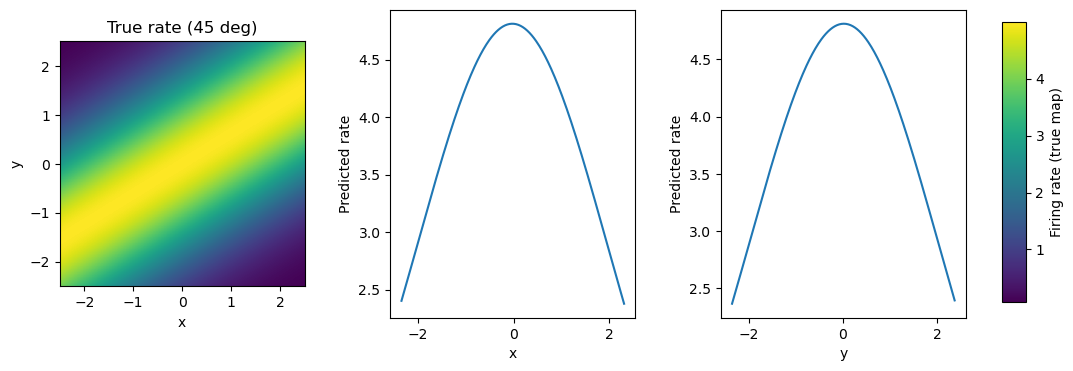

In [49]:
# --- Build the grid for the heatmap ---
grid = np.linspace(-2.5, 2.5, 160)
Xg, Yg = np.meshgrid(grid, grid)
Ug = rotated_coord(Xg, Yg, mu, theta, wrap=False)
eta_true_grid = alpha - ((Ug - mu) ** 2) / (2 * sigma_u ** 2)
lam_true_grid = np.exp(eta_true_grid)

# --- Marginal predictions from Model A ---
x_grid = np.linspace(np.percentile(x, 1), np.percentile(x, 99), 300)
y_grid = np.linspace(np.percentile(y, 1), np.percentile(y, 99), 300)
x_mean = float(np.mean(x))
y_mean = float(np.mean(y))

df_x = pd.DataFrame({
    "x": x_grid,
    "y": y_mean,
    "x2": x_grid**2,
    "y2": np.full_like(x_grid, y_mean**2),
})
pred_x = modelA.predict(df_x[["x","y","x2","y2"]]).to_numpy()

df_y = pd.DataFrame({
    "x": x_mean,
    "y": y_grid,
    "x2": np.full_like(y_grid, x_mean**2),
    "y2": y_grid**2,
})
pred_y = modelA.predict(df_y[["x","y","x2","y2"]]).to_numpy()

# --- Plot: 1 row, 3 columns ---
fig = plt.figure(figsize=(12, 4))

# Panel 1: heatmap (square), colorbar to far right
ax1 = plt.subplot(1, 3, 1)
ax1.set_aspect('equal')
im = ax1.imshow(lam_true_grid, origin="lower",
                extent=[grid.min(), grid.max(), grid.min(), grid.max()])
ax1.set_title(f"True rate ({theta} deg)")
ax1.set_xlabel("x"); ax1.set_ylabel("y")

# Panel 2: marginal vs x
ax2 = plt.subplot(1, 3, 2)
ax2.plot(x_grid, pred_x)
ax2.set_xlabel("x"); ax2.set_ylabel("Predicted rate")

# Panel 3: marginal vs y
ax3 = plt.subplot(1, 3, 3)
ax3.plot(y_grid, pred_y)
ax3.set_xlabel("y"); ax3.set_ylabel("Predicted rate")

# Colorbar to the right of all panels
plt.subplots_adjust(right=0.88, wspace=0.35)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Firing rate (true map)")
plt.savefig(current_file_path / f'figs/glm_theta_{theta}.png')

plt.show()